# Graph Data Science Midterm

Name: Illona Anindya
Student ID: 24031554222
CLass: 2024INT
Lecturer: Ibnu Febry Kurniawan, S.Kom., M.Sc., Ph.D.

**Dataset Used**

P1 (training): 11/07/2015 00:00:00 - 20/07/2015 00:00:00 (9 days)
P2 (testing) 21/07/2015 00:00:00 - 30/07/2015 00:00:00 (9 days)

## 0. Setup

In [1]:
%matplotlib inline
import inspect
import math
import os
import platform
import time
from collections import deque
from collections.abc import Callable, Iterable, Sequence
from dataclasses import dataclass
from importlib.metadata import version
from pathlib import Path
from typing import Protocol

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import display
from matplotlib.lines import Line2D
from neo4j import Driver, GraphDatabase, ManagedTransaction, Result, RoutingControl, Session
from scipy.sparse.csgraph import connected_components
from sklearn.preprocessing import normalize
from tqdm import tqdm

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

### Helper functions
All helper code used in this notebook is defined in the cells below (configuration, Cypher queries, data wrangling,
Neo4j access, VSM, projection, similarity, recommenders, metrics, and plotting), so the notebook runs on its own.

In [2]:
# Configuration: paths, periods, weights, model parameters, Neo4j connection
DATA_DIR = Path("data")
RAW_EVENTS_CSV = DATA_DIR / "events.csv"
FILTERED_EVENTS_CSV = DATA_DIR / "filtered_events.csv"

MS_PER_DAY = 86_400_000


def load_env_file(path: str = ".env") -> None:
    env_file = Path(path)
    if env_file.exists():
        for line in env_file.read_text(encoding="utf-8").splitlines():
            if "=" in line and not line.lstrip().startswith("#"):
                key, value = line.split("=", 1)
                os.environ.setdefault(key.strip(), value.strip())


load_env_file()


@dataclass(frozen=True)
class Period:

    name: str
    start: str
    end: str

    @property
    def start_ms(self) -> int:
        return _to_epoch_ms(self.start)

    @property
    def end_ms(self) -> int:
        return _to_epoch_ms(self.end)

    @property
    def days(self) -> float:
        return (self.end_ms - self.start_ms) / MS_PER_DAY


def _to_epoch_ms(moment: str) -> int:
    return int(pd.Timestamp(moment, tz="UTC").value // 1_000_000)


# Individual periods (must not be identical to any other student's choice in the class)
P1 = Period("P1", "2015-07-11 00:00:00", "2015-07-20 00:00:00")  # training fold
P2 = Period("P2", "2015-07-21 00:00:00", "2015-07-30 00:00:00")  # testing fold
PERIODS = (P1, P2)

# CSV event to Neo4j relationship type
EVENT_TO_RELATIONSHIP = {
    "view": "VIEWED",
    "addtocart": "ADDED_TO_CART",
    "transaction": "BOUGHT",
}

# Implicit feedback weights (shopping funnel stage). A (visitor, item) pair keeps its maximum weight.
RELATIONSHIP_WEIGHTS = {"VIEWED": 1.0, "ADDED_TO_CART": 2.0, "BOUGHT": 3.0}

RANDOM_SEED = 42
K_NEIGHBORS = 5
N_RECOMMENDATIONS = 3
EVAL_CUTOFF = 5


@dataclass(frozen=True)
class Neo4jSettings:
    uri: str = os.getenv("NEO4J_URI", "neo4j://127.0.0.1:7687")
    user: str = os.getenv("NEO4J_USER", "neo4j")
    password: str = os.getenv("NEO4J_PASSWORD", "password")
    database: str = os.getenv("NEO4J_DATABASE", "neo4j")

In [3]:
class cypher:
    
    RESET_DATABASE = """
MATCH (n)
CALL (n) { DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS
"""

    CONSTRAINTS = (
        "CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE",
        "CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE",
    )

    # Import
    IMPORT_BATCH = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
WITH v, i, row
CALL (v, i, row) {
    WITH v, i, row WHERE row.event = 'view'
    CREATE (v)-[:VIEWED {timestamp: row.timestamp, period: row.period}]->(i)
  UNION ALL
    WITH v, i, row WHERE row.event = 'addtocart'
    CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp, period: row.period}]->(i)
  UNION ALL
    WITH v, i, row WHERE row.event = 'transaction'
    CREATE (v)-[:BOUGHT {timestamp: row.timestamp, period: row.period,
                         transactionId: row.transactionid}]->(i)
}
"""

    NODE_COMPOSITION = """
MATCH (n)
RETURN labels(n)[0] AS node_type, count(*) AS total
ORDER BY total DESC
"""

    RELATIONSHIP_COMPOSITION = """
MATCH ()-[r]->()
RETURN type(r) AS relationship_type, count(*) AS total
ORDER BY total DESC
"""

    PERIOD_COMPOSITION = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.period IS NOT NULL
RETURN r.period AS period,
       type(r) AS relationship_type,
       count(*) AS relationships,
       count(DISTINCT v) AS unique_visitors,
       count(DISTINCT i) AS unique_items
ORDER BY period, relationships DESC
"""

    ACTIVE_NODES_PER_PERIOD = """
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.period IS NOT NULL
RETURN r.period AS period,
       count(DISTINCT v) AS active_visitors,
       count(DISTINCT i) AS active_items,
       count(*) AS total_relationships
ORDER BY period
"""

    NODES_IN_BOTH_PERIODS = """
MATCH (n)
WHERE n:Visitor OR n:Item
WITH n, COLLECT {
    MATCH (n)-[r]-()
    WHERE r.period IS NOT NULL
    RETURN DISTINCT r.period
} AS periods
RETURN labels(n)[0] AS node_type,
       sum(CASE WHEN periods = ['P1'] THEN 1 ELSE 0 END) AS only_P1,
       sum(CASE WHEN periods = ['P2'] THEN 1 ELSE 0 END) AS only_P2,
       sum(CASE WHEN size(periods) = 2 THEN 1 ELSE 0 END) AS both_P1_and_P2
ORDER BY node_type DESC
"""

    # Data for the VSM
    INTERACTIONS_IN_PERIOD = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.period = $period
RETURN v.visitorId AS visitorId, i.itemId AS itemId, type(r) AS relType
"""

    COSINE_TOP_ITEMS = """
MATCH (ref:Item {itemId: $refItemId})<-[r1]-(v:Visitor)
WHERE r1.period = $period
WITH ref, v, max($weights[type(r1)]) AS wRef
MATCH (v)-[r2]->(other:Item)
WHERE r2.period = $period AND other <> ref
WITH ref, other, v, wRef, max($weights[type(r2)]) AS wOther
WITH ref, other, sum(wRef * wOther) AS dot, count(v) AS commonVisitors
CALL (ref) {
    MATCH (ref)<-[r]-(u:Visitor) WHERE r.period = $period
    WITH u, max($weights[type(r)]) AS w
    RETURN sqrt(sum(w * w)) AS normRef
}
CALL (other) {
    MATCH (other)<-[r]-(u:Visitor) WHERE r.period = $period
    WITH u, max($weights[type(r)]) AS w
    RETURN sqrt(sum(w * w)) AS normOther
}
WITH other, commonVisitors, dot / (normRef * normOther) AS cosine
RETURN other.itemId AS itemId, cosine, commonVisitors
ORDER BY round(cosine, 10) DESC, commonVisitors DESC, itemId ASC
LIMIT $limit
"""

    DELETE_SIMILARITIES = """
MATCH ()-[s]->() WHERE type(s) = 'SIMILAR'
CALL (s) { DELETE s } IN TRANSACTIONS OF 10000 ROWS
"""

    WRITE_SIMILARITIES = """
UNWIND $rows AS row
MATCH (a:Item {itemId: row.sourceId})
MATCH (b:Item {itemId: row.targetId})
MERGE (a)-[s:SIMILAR]->(b)
SET s.score = row.score,
    s.rank = row.rank,
    s.commonVisitors = row.common,
    s.metric = 'cosine',
    s.period = $period
"""

    SIMILAR_ITEMS_OF = """
MATCH (ref:Item {itemId: $refItemId})-[s:SIMILAR]->(other:Item)
RETURN ref.itemId AS refItemId, s.rank AS rank, other.itemId AS itemId,
       s.score AS score, s.commonVisitors AS commonVisitors, s.metric AS metric
ORDER BY s.rank
"""

    SIMILARITY_COUNT = """
MATCH ()-[s]->() WHERE type(s) = 'SIMILAR'
RETURN count(s) AS similar_relationships
"""

    INTERACTION_SUBGRAPH = """
MATCH (ref:Item {itemId: $refItemId})<-[r1]-(v:Visitor)-[r2]->(other:Item)
WHERE r1.period = $period AND r2.period = $period AND other.itemId IN $itemIds
RETURN DISTINCT 'Visitor' AS sourceLabel, v.visitorId AS sourceId, type(r1) AS relType,
       'Item' AS targetLabel, ref.itemId AS targetId
UNION
MATCH (ref:Item {itemId: $refItemId})<-[r1]-(v:Visitor)-[r2]->(other:Item)
WHERE r1.period = $period AND r2.period = $period AND other.itemId IN $itemIds
RETURN DISTINCT 'Visitor' AS sourceLabel, v.visitorId AS sourceId, type(r2) AS relType,
       'Item' AS targetLabel, other.itemId AS targetId
"""

    SIMILARITY_SUBGRAPH = """
MATCH (ref:Item {itemId: $refItemId})-[s:SIMILAR]->(other:Item)
RETURN 'Item' AS sourceLabel, ref.itemId AS sourceId, 'SIMILAR' AS relType,
       'Item' AS targetLabel, other.itemId AS targetId, s.score AS score
"""

    SCHEMA_RELATIONSHIPS = """
MATCH (a)-[r]->(b)
RETURN DISTINCT labels(a)[0] AS source_label, type(r) AS relationship, labels(b)[0] AS target_label
ORDER BY relationship
"""

    RECOMMEND_FROM_SIMILAR = """
MATCH (v:Visitor {visitorId: $visitorId})-[r]->(seen:Item)
WHERE r.period = $period
WITH v, seen, max($weights[type(r)]) AS w
MATCH (seen)-[s:SIMILAR]->(candidate:Item)
WHERE NOT EXISTS { MATCH (v)-[r2]->(candidate) WHERE r2.period = $period }
WITH candidate, sum(w * s.score) AS score
RETURN candidate.itemId AS itemId, score
ORDER BY round(score, 10) DESC, itemId ASC
LIMIT $limit
"""

    WRITE_RECOMMENDATIONS = """
MATCH (v:Visitor {visitorId: $visitorId})
OPTIONAL MATCH (v)-[old]->() WHERE type(old) = 'RECOMMENDED'
DELETE old
WITH DISTINCT v
UNWIND $rows AS row
MATCH (i:Item {itemId: row.itemId})
CREATE (v)-[:RECOMMENDED {rank: row.rank, score: row.score, k: $k, method: $method}]->(i)
"""

    RECOMMENDATIONS_OF = """
MATCH (v:Visitor {visitorId: $visitorId})-[rec:RECOMMENDED]->(i:Item)
RETURN v.visitorId AS visitorId, rec.rank AS rank, i.itemId AS itemId,
       rec.score AS score, rec.k AS k, rec.method AS method
ORDER BY rec.rank
"""

In [4]:
EVENT_COLUMNS = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
CSV_DTYPES = {
    "timestamp": "int64",
    "visitorid": "int64",
    "event": "string",
    "itemid": "int64",
    "transactionid": "Int64",
}


def load_events(path: str | Path) -> pd.DataFrame:
    return pd.read_csv(path, dtype=CSV_DTYPES)


def filter_periods(events: pd.DataFrame, periods: tuple[Period, ...] = PERIODS) -> pd.DataFrame:
    parts = [
        events.loc[(events["timestamp"] >= p.start_ms) & (events["timestamp"] < p.end_ms)].assign(period=p.name)
        for p in periods
    ]
    filtered = pd.concat(parts, ignore_index=True)
    filtered = filtered.drop_duplicates(subset=EVENT_COLUMNS)
    return filtered.sort_values(["timestamp", "visitorid", "itemid"], kind="stable").reset_index(drop=True)


def count_exact_duplicates(events: pd.DataFrame, periods: tuple[Period, ...] = PERIODS) -> pd.Series:
    return pd.Series(
        {
            p.name: int(
                events.loc[(events["timestamp"] >= p.start_ms) & (events["timestamp"] < p.end_ms)]
                .duplicated(subset=EVENT_COLUMNS)
                .sum()
            )
            for p in periods
        },
        name="dropped_duplicates",
    )


def summarize_periods(events: pd.DataFrame) -> pd.DataFrame:
    per_event = events.pivot_table(index="period", columns="event", values="timestamp", aggfunc="count", fill_value=0)
    stamps = pd.to_datetime(events["timestamp"], unit="ms", utc=True)
    grouped = events.assign(_dt=stamps).groupby("period")
    summary = pd.DataFrame(
        {
            "events": grouped.size(),
            "unique_visitors": grouped["visitorid"].nunique(),
            "unique_items": grouped["itemid"].nunique(),
            "first_event_utc": grouped["_dt"].min(),
            "last_event_utc": grouped["_dt"].max(),
        }
    )
    return summary.join(per_event)


def save_events(events: pd.DataFrame, path: str | Path) -> None:
    events.to_csv(path, index=False)

def create_driver(settings: Neo4jSettings | None = None) -> Driver:
    settings = settings or Neo4jSettings()
    driver = GraphDatabase.driver(settings.uri, auth=(settings.user, settings.password))
    driver.verify_connectivity()
    return driver


def read_df(driver: Driver, cypher: str, database: str, **params) -> pd.DataFrame:
    return driver.execute_query(
        cypher,
        parameters_=params,
        database_=database,
        routing_=RoutingControl.READ,
        result_transformer_=Result.to_df,
    )


def write(driver: Driver, cypher: str, database: str, **params) -> dict:
    summary = driver.execute_query(
        cypher,
        parameters_=params,
        database_=database,
        routing_=RoutingControl.WRITE,
    ).summary
    return {k: v for k, v in vars(summary.counters).items() if v and not k.startswith("_")}


def write_in_batches(driver: Driver, cypher: str, rows: list[dict], database: str, batch_size: int = 10_000, **params) -> int:
    for start in range(0, len(rows), batch_size):
        write(driver, cypher, database, rows=rows[start : start + batch_size], **params)
    return len(rows)


def run_autocommit(driver: Driver, cypher: str, database: str, **params) -> None:
    with driver.session(database=database) as session:
        session.run(cypher, params).consume()


# Batch import of the event CSV into Neo4j
DEFAULT_BATCH_SIZE = 5000


def reset_database(driver: Driver, database: str) -> None:
    run_autocommit(driver, cypher.RESET_DATABASE, database)


def create_constraints(session: Session) -> None:
    for statement in cypher.CONSTRAINTS:
        session.run(statement).consume()


def import_batch(tx: ManagedTransaction, batch: list[dict]) -> None:
    tx.run(cypher.IMPORT_BATCH, batch=batch).consume()


def to_records(chunk: pd.DataFrame) -> list[dict]:
    clean = chunk.astype(object).where(chunk.notna(), None)
    return clean.to_dict(orient="records")


def count_rows(csv_path: str | Path) -> int:
    with open(csv_path, encoding="utf-8") as handle:
        return sum(1 for _ in handle) - 1


def import_events(
    driver: Driver, csv_path: str | Path, database: str, batch_size: int = DEFAULT_BATCH_SIZE, progress: bool = True
) -> int:
    total_rows = count_rows(csv_path)
    chunks = pd.read_csv(csv_path, chunksize=batch_size, dtype=CSV_DTYPES)
    with driver.session(database=database) as session:
        create_constraints(session)
        total_chunks = math.ceil(total_rows / batch_size)
        for chunk in tqdm(chunks, total=total_chunks, desc="Importing batches", disable=not progress):
            session.execute_write(import_batch, to_records(chunk))
    return total_rows

In [5]:
# Vector Space Model (VSM) built from Visitor and Item interactions
@dataclass(frozen=True)
class VectorSpace:
    matrix: sp.csr_matrix  # rows = vectorised objects, columns = dimensions
    row_ids: np.ndarray  # original id of each row (ascending)
    col_ids: np.ndarray  # original id of each column (ascending)
    row_label: str
    col_label: str

    def index_of(self, entity_id: int) -> int:
        pos = int(np.searchsorted(self.row_ids, entity_id))
        if pos == len(self.row_ids) or self.row_ids[pos] != entity_id:
            raise KeyError(f"{self.row_label} {entity_id} is not in the VSM")
        return pos

    def vector(self, entity_id: int) -> pd.Series:
        row = self.matrix.getrow(self.index_of(entity_id))
        return pd.Series(row.data, index=pd.Index(self.col_ids[row.indices], name=self.col_label), name="weight")

    def transpose(self) -> "VectorSpace":
        return VectorSpace(self.matrix.T.tocsr(), self.col_ids, self.row_ids, self.col_label, self.row_label)


def pair_weights(interactions: pd.DataFrame, weights: dict[str, float] = RELATIONSHIP_WEIGHTS) -> pd.DataFrame:
    weighted = interactions.assign(weight=interactions["relType"].map(weights))
    return weighted.groupby(["visitorId", "itemId"], as_index=False)["weight"].max()


def build_user_space(pairs: pd.DataFrame) -> VectorSpace:
    users = np.sort(pairs["visitorId"].unique())
    items = np.sort(pairs["itemId"].unique())
    rows = np.searchsorted(users, pairs["visitorId"].to_numpy())
    cols = np.searchsorted(items, pairs["itemId"].to_numpy())
    matrix = sp.csr_matrix(
        (pairs["weight"].to_numpy(dtype=np.float64), (rows, cols)), shape=(len(users), len(items))
    )
    return VectorSpace(matrix, users, items, "Visitor", "Item")


def describe(space: VectorSpace) -> pd.Series:
    m = space.matrix
    n_rows, n_cols = m.shape
    nnz_per_row = np.diff(m.indptr)
    density = m.nnz / (n_rows * n_cols)
    values, counts = np.unique(m.data, return_counts=True)
    return pd.Series(
        {
            "vectorised object (rows)": space.row_label,
            "dimension / feature (columns)": space.col_label,
            "shape": f"{n_rows:,} x {n_cols:,}",
            "number of vectors": n_rows,
            "vector dimension": n_cols,
            "non-zero elements (nnz)": m.nnz,
            "density": density,
            "sparsity": 1 - density,
            "mean nnz per vector": nnz_per_row.mean(),
            "median nnz per vector": float(np.median(nnz_per_row)),
            "max nnz per vector": int(nnz_per_row.max()),
            "% vectors with only 1 nnz": 100 * float((nnz_per_row == 1).mean()),
            "weight distribution {weight: count}": dict(zip(values.tolist(), counts.tolist())),
            "CSR memory (MB)": (m.data.nbytes + m.indices.nbytes + m.indptr.nbytes) / 1e6,
            "memory if dense float64 (GB)": n_rows * n_cols * 8 / 1e9,
        },
        name=f"{space.row_label} VSM",
    )


def co_occurrence(space: VectorSpace) -> sp.csr_matrix:
    binary = (space.matrix > 0).astype(np.int32)
    adjacency = (binary @ binary.T).tocsr()
    adjacency.setdiag(0)
    adjacency.eliminate_zeros()
    adjacency.sort_indices()
    return adjacency

def projection_stats(space: VectorSpace) -> pd.Series:
    started = time.perf_counter()
    adjacency = co_occurrence(space)
    seconds = time.perf_counter() - started

    n = adjacency.shape[0]
    edges = adjacency.nnz // 2
    degree = np.diff(adjacency.indptr)
    _, labels = connected_components(adjacency, directed=False)
    sizes = np.bincount(labels)
    return pd.Series(
        {
            "nodes": n,
            "edges": edges,
            "possible node pairs n(n-1)/2": n * (n - 1) // 2,
            "density": 2 * edges / (n * (n - 1)),
            "mean degree": degree.mean(),
            "median degree": float(np.median(degree)),
            "max degree": int(degree.max()),
            "isolated nodes (degree 0)": int((degree == 0).sum()),
            "% isolated nodes": 100 * float((degree == 0).mean()),
            "connected components (excluding isolated nodes)": int((sizes > 1).sum()),
            "largest component size": int(sizes.max()),
            "% nodes in largest component": 100 * sizes.max() / n,
            "adjacency CSR memory (MB)": (adjacency.data.nbytes + adjacency.indices.nbytes + adjacency.indptr.nbytes) / 1e6,
            "projection build time (s)": seconds,
        },
        name=f"{space.row_label}-{space.row_label} projection",
        dtype=object,
    )

def snowball_sample(adjacency: sp.csr_matrix, start: int, max_nodes: int) -> list[int]:
    seen, queue = {start}, deque([start])
    while queue and len(seen) < max_nodes:
        node = queue.popleft()
        for neighbor in adjacency.indices[adjacency.indptr[node] : adjacency.indptr[node + 1]]:
            if len(seen) >= max_nodes:
                break
            if neighbor not in seen:
                seen.add(int(neighbor))
                queue.append(int(neighbor))
    return sorted(seen)

def sample_projection_graph(space: VectorSpace, max_nodes: int, seed: int) -> nx.Graph:
    adjacency = co_occurrence(space)
    _, labels = connected_components(adjacency, directed=False)
    largest = np.flatnonzero(labels == np.bincount(labels).argmax())
    start = int(np.random.default_rng(seed).choice(largest))
    nodes = snowball_sample(adjacency, start, max_nodes)
    sub = adjacency[nodes][:, nodes].tocoo()
    graph = nx.Graph(name=f"{space.row_label} projection sample")
    graph.add_nodes_from(int(space.row_ids[i]) for i in nodes)
    graph.add_weighted_edges_from(
        (int(space.row_ids[nodes[a]]), int(space.row_ids[nodes[b]]), int(w))
        for a, b, w in zip(sub.row, sub.col, sub.data)
        if a < b
    )
    return graph

# Cosine similarity
SCORE_DECIMALS = 10
COLUMNS = ["sourceId", "rank", "targetId", "score", "common"]

def cosine_matrix(space: VectorSpace) -> sp.csr_matrix:
    unit = normalize(space.matrix, norm="l2", axis=1)
    similarity = (unit @ unit.T).tocsr()
    similarity.setdiag(0)
    similarity.eliminate_zeros()
    similarity.sort_indices()
    return similarity

def _rank(ids: np.ndarray, scores: np.ndarray, common: np.ndarray, k: int) -> np.ndarray:
    order = np.lexsort((ids, -common, -np.round(scores, SCORE_DECIMALS)))
    return order[:k]

def top_k_neighbors(space: VectorSpace, k: int) -> pd.DataFrame:
    similarity = cosine_matrix(space)
    common = co_occurrence(space)
    if not np.array_equal(similarity.indptr, common.indptr):
        raise ValueError("Cosine and co-occurrence must have the same non-zero pattern")

    parts = []
    for row in range(similarity.shape[0]):
        lo, hi = similarity.indptr[row], similarity.indptr[row + 1]
        if lo == hi:
            continue
        targets = space.row_ids[similarity.indices[lo:hi]]
        scores = similarity.data[lo:hi]
        shared = common.data[lo:hi]
        best = _rank(targets, scores, shared, k)
        parts.append(
            pd.DataFrame(
                {
                    "sourceId": space.row_ids[row],
                    "rank": np.arange(1, len(best) + 1),
                    "targetId": targets[best],
                    "score": scores[best],
                    "common": shared[best],
                }
            )
        )
    return pd.concat(parts, ignore_index=True)[COLUMNS]

def most_similar(space: VectorSpace, entity_id: int, n: int) -> pd.DataFrame:
    index = space.index_of(entity_id)
    unit = normalize(space.matrix, norm="l2", axis=1)
    binary = (space.matrix > 0).astype(np.int32)
    scores = (unit @ unit[index].T).toarray().ravel()
    shared = (binary @ binary[index].T).toarray().ravel()
    scores[index] = 0.0
    candidates = np.flatnonzero(scores > 0)
    best = candidates[_rank(space.row_ids[candidates], scores[candidates], shared[candidates], n)]
    return pd.DataFrame(
        {
            "sourceId": entity_id,
            "rank": np.arange(1, len(best) + 1),
            "targetId": space.row_ids[best],
            "score": scores[best],
            "common": shared[best],
        }
    )[COLUMNS]

In [6]:
# KNN based top N recommenders
class Recommender(Protocol):
    name: str

    def recommend(self, user_id: int, n: int) -> pd.DataFrame: ...

def _top_n(scores: pd.Series, n: int) -> pd.DataFrame:
    ranked = (
        scores.rename("score")
        .rename_axis("itemId")
        .reset_index()
        .assign(_key=lambda d: d["score"].round(SCORE_DECIMALS))
        .sort_values(["_key", "itemId"], ascending=[False, True], kind="stable")
        .head(n)
        .drop(columns="_key")
        .reset_index(drop=True)
    )
    ranked.insert(0, "rank", np.arange(1, len(ranked) + 1))
    return ranked

class ItemKNNRecommender:
    name = "Item-KNN"

    def __init__(self, user_space: VectorSpace, k: int):
        self.user_space = user_space
        self.k = k
        self.neighbors = top_k_neighbors(user_space.transpose(), k)

    def contributions(self, user_id: int) -> pd.DataFrame:
        history = self.user_space.vector(user_id)
        table = self.neighbors[
            self.neighbors["sourceId"].isin(history.index) & ~self.neighbors["targetId"].isin(history.index)
        ]
        table = table.assign(r_ui=table["sourceId"].map(history))
        return table.assign(contribution=table["score"] * table["r_ui"]).reset_index(drop=True)

    def recommend(self, user_id: int, n: int) -> pd.DataFrame:
        parts = self.contributions(user_id)
        return _top_n(parts.groupby("targetId")["contribution"].sum(), n)

class UserKNNRecommender:
    name = "User-KNN"

    def __init__(self, user_space: VectorSpace, k: int):
        self.user_space = user_space
        self.k = k

    def neighbors(self, user_id: int) -> pd.DataFrame:
        return most_similar(self.user_space, user_id, self.k)

    def recommend(self, user_id: int, n: int) -> pd.DataFrame:
        seen = set(self.user_space.vector(user_id).index)
        totals: dict[int, float] = {}
        for neighbor_id, similarity in self.neighbors(user_id)[["targetId", "score"]].itertuples(index=False):
            for item, weight in self.user_space.vector(int(neighbor_id)).items():
                if item not in seen:
                    totals[item] = totals.get(item, 0.0) + similarity * weight
        return _top_n(pd.Series(totals, dtype=float), n)

class PopularityRecommender:
    name = "Popularity"

    def __init__(self, user_space: VectorSpace):
        self.user_space = user_space
        popularity = np.asarray((user_space.matrix > 0).sum(axis=0)).ravel()
        self.popularity = pd.Series(popularity.astype(float), index=user_space.col_ids)

    def recommend(self, user_id: int, n: int) -> pd.DataFrame:
        seen = self.user_space.vector(user_id).index
        return _top_n(self.popularity.drop(seen), n)

def hit_at_k(recommended: Sequence[int], relevant: set[int], k: int) -> int:
    return int(any(item in relevant for item in recommended[:k]))

def dcg_at_k(recommended: Sequence[int], relevant: set[int], k: int) -> float:
    return float(sum(1.0 / np.log2(rank + 1) for rank, item in enumerate(recommended[:k], start=1) if item in relevant))

def idcg_at_k(n_relevant: int, k: int) -> float:
    return float(sum(1.0 / np.log2(rank + 1) for rank in range(1, min(k, n_relevant) + 1)))

def ndcg_at_k(recommended: Sequence[int], relevant: set[int], k: int) -> float:
    ideal = idcg_at_k(len(relevant), k)
    return dcg_at_k(recommended, relevant, k) / ideal if ideal > 0 else 0.0

def gain_table(recommended: Sequence[int], relevant: set[int], k: int) -> pd.DataFrame:
    rows = []
    for rank, item in enumerate(recommended[:k], start=1):
        rel = int(item in relevant)
        discount = 1.0 / np.log2(rank + 1)
        rows.append({"rank": rank, "itemId": item, "rel_i": rel, "1/log2(i+1)": discount, "gain": rel * discount})
    return pd.DataFrame(rows)

def ground_truth(test_interactions: pd.DataFrame) -> dict[int, set[int]]:
    return {int(user): set(items.tolist()) for user, items in test_interactions.groupby("visitorId")["itemId"]}

def eligible_users(train_space: VectorSpace, truth: dict[int, set[int]]) -> np.ndarray:
    return np.intersect1d(train_space.row_ids, np.fromiter(truth.keys(), dtype=np.int64))

def pick_random_user(
    candidates: np.ndarray, seed: int, is_valid: Callable[[int], bool] = lambda _: True
) -> tuple[int, list[int]]:
    rejected: list[int] = []
    for user in np.random.default_rng(seed).permutation(np.sort(candidates)):
        if is_valid(int(user)):
            return int(user), rejected
        rejected.append(int(user))
    raise ValueError("No candidate satisfies the condition")
    
def evaluate(
    recommender: Recommender, users: Iterable[int], truth: dict[int, set[int]], n: int, k: int
) -> pd.DataFrame:
    rows = []
    for user in users:
        recommended = recommender.recommend(int(user), n)["itemId"].tolist()
        relevant = truth[int(user)]
        rows.append(
            {
                "visitorId": int(user),
                "n_recommended": len(recommended),
                "n_relevant": len(relevant),
                f"Hit@{k}": hit_at_k(recommended, relevant, k),
                f"NDCG@{k}": ndcg_at_k(recommended, relevant, k),
            }
        )
    return pd.DataFrame(rows)

In [7]:
# Graph visualisation
NODE_COLORS = {"Visitor": "#4C72B0", "Item": "#DD8452", "Person": "#55A868"}
EDGE_COLORS = {
    "VIEWED": "#9E9E9E",
    "ADDED_TO_CART": "#2CA02C",
    "BOUGHT": "#D62728",
    "SIMILAR": "#8172B3",
    "RECOMMENDED": "#E377C2",
    "KNOWS": "#555555",
}
DASHED = {"SIMILAR", "RECOMMENDED"}

def graph_from_rows(rows: pd.DataFrame) -> nx.DiGraph:
    strength = {rel: RELATIONSHIP_WEIGHTS.get(rel, 0.0) for rel in rows["relType"].unique()}
    ordered = rows.assign(_s=rows["relType"].map(strength)).sort_values("_s", kind="stable")
    graph = nx.DiGraph()
    for row in ordered.itertuples(index=False):
        source, target = f"{row.sourceLabel}:{row.sourceId}", f"{row.targetLabel}:{row.targetId}"
        graph.add_node(source, label=row.sourceLabel, entity_id=row.sourceId)
        graph.add_node(target, label=row.targetLabel, entity_id=row.targetId)
        score = getattr(row, "score", None)
        graph.add_edge(source, target, relType=row.relType, score=None if pd.isna(score) else float(score))
    return graph

def draw_property_graph(
    graph: nx.DiGraph,
    ax: plt.Axes,
    title: str,
    pos: dict | None = None,
    highlight: set[str] | None = None,
    label_labels: tuple[str, ...] = ("Item", "Person"),
) -> dict:
    pos = pos or nx.spring_layout(graph, seed=42, k=0.9)
    highlight = highlight or set()
    handles = []
    for label, color in NODE_COLORS.items():
        nodes = [n for n, d in graph.nodes(data=True) if d["label"] == label]
        if nodes:
            sizes = [700 if n in highlight else (420 if label != "Visitor" else 120) for n in nodes]
            nx.draw_networkx_nodes(graph, pos, nodelist=nodes, node_color=color, node_size=sizes, ax=ax,
                                   edgecolors=["black" if n in highlight else "white" for n in nodes])
            handles.append(Line2D([], [], marker="o", linestyle="none", markersize=8, markerfacecolor=color,
                                  markeredgecolor="white", label=label))
    for rel, color in EDGE_COLORS.items():
        edges = [(u, v) for u, v, d in graph.edges(data=True) if d["relType"] == rel]
        if edges:
            dashed = rel in DASHED
            nx.draw_networkx_edges(graph, pos, edgelist=edges, edge_color=color, ax=ax, arrows=True, arrowsize=10,
                                   style="dashed" if dashed else "solid", width=2.2 if dashed else 1.0,
                                   connectionstyle="arc3,rad=0.08")
            handles.append(Line2D([], [], color=color, linestyle="dashed" if dashed else "solid",
                                  linewidth=2 if dashed else 1, label=rel))
    labels = {n: str(d["entity_id"]) for n, d in graph.nodes(data=True) if d["label"] in label_labels}
    nx.draw_networkx_labels(graph, pos, labels=labels, font_size=7, ax=ax)
    scores = {(u, v): f"{d['score']:.3f}" for u, v, d in graph.edges(data=True) if d.get("score") is not None}
    if scores:
        nx.draw_networkx_edge_labels(graph, pos, edge_labels=scores, font_size=7, font_color=EDGE_COLORS["SIMILAR"], ax=ax)
    ax.set_title(title)
    ax.legend(handles=handles, loc="lower left", fontsize=7)
    ax.axis("off")
    return pos

def draw_projection(graph: nx.Graph, ax: plt.Axes, title: str, color: str) -> None:
    pos = nx.spring_layout(graph, seed=42)
    degree = dict(graph.degree())
    widths = [0.5 + 0.8 * np.log1p(d["weight"]) for _, _, d in graph.edges(data=True)]
    nx.draw_networkx_edges(graph, pos, width=widths, alpha=0.35, ax=ax)
    nx.draw_networkx_nodes(graph, pos, node_color=color, node_size=[min(250, 15 + 3 * degree[n]) for n in graph.nodes],
                           edgecolors="white", ax=ax)
    ax.set_title(f"{title}\n{graph.number_of_nodes()} nodes, {graph.number_of_edges()} edges")
    ax.axis("off")

def plot_vector_lengths(spaces: dict[str, VectorSpace], ax: plt.Axes) -> None:
    for name, space in spaces.items():
        lengths = np.diff(space.matrix.indptr)
        values, counts = np.unique(lengths, return_counts=True)
        ax.loglog(values, counts, marker="o", linestyle="none", markersize=3, label=name)
    ax.set_xlabel("non-zero components per vector")
    ax.set_ylabel("number of vectors")
    ax.set_title("VSM vector length distribution")
    ax.legend()

In [8]:
settings = Neo4jSettings()
DB = settings.database
driver = create_driver(settings)  # calls verify_connectivity(): fails fast if the server is down

print("Python", platform.python_version())
for package in ["neo4j", "pandas", "numpy", "scipy", "scikit-learn", "networkx", "matplotlib", "tqdm",
                "imdbpy", "nose", "cinemagoerng", "imdbinfo"]:
    print(f"{package:<13} {version(package)}")
read_df(driver, "CALL dbms.components() YIELD name, versions, edition "
                "RETURN name, versions[0] AS version, edition", DB)

Python 3.10.20
neo4j         6.4.1
pandas        2.3.3
numpy         2.2.6
scipy         1.15.3
scikit-learn  1.7.2
networkx      3.4.2
matplotlib    3.10.9
tqdm          4.70.1
imdbpy        2020.9.25
nose          1.3.7
cinemagoerng  0.4
imdbinfo      0.11.0


,name,version,edition
0,Neo4j Kernel,2026.09.0,enterprise
1,Cypher,5,


## 1. Preliminary Tasks

### 1.1 Environment Preparation

(Done at CMD)

### 1.2 Learning the Neo4j Driver

In [9]:
from neo4j import GraphDatabase, RoutingControl

URI = settings.uri
AUTH = (settings.user, settings.password)


def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )


def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])


with GraphDatabase.driver(URI, auth=AUTH) as tutorial_driver:
    add_friend(tutorial_driver, "Arthur", "Guinevere")
    add_friend(tutorial_driver, "Arthur", "Lancelot")
    add_friend(tutorial_driver, "Arthur", "Merlin")
    print_friends(tutorial_driver, "Arthur")

Guinevere
Lancelot
Merlin


,person,out_degree,in_degree
0,Arthur,3,0
1,Guinevere,0,1
2,Lancelot,0,1
3,Merlin,0,1


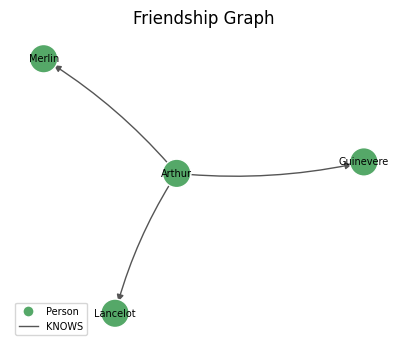

In [10]:
friend_rows = read_df(driver, '''
MATCH (a:Person)-[r:KNOWS]->(b:Person)
RETURN 'Person' AS sourceLabel, a.name AS sourceId, type(r) AS relType,
       'Person' AS targetLabel, b.name AS targetId
''', DB)
friend_degree = read_df(driver, '''
MATCH (p:Person)
RETURN p.name AS person,
       COUNT { (p)-[:KNOWS]->() } AS out_degree,
       COUNT { (p)<-[:KNOWS]-() } AS in_degree
ORDER BY out_degree DESC, person
''', DB)
display(friend_degree)

fig, ax = plt.subplots(figsize=(5, 4))
draw_property_graph(graph_from_rows(friend_rows), ax, "Friendship Graph")
plt.show()

In [11]:
display(read_df(driver, "SHOW DATABASES YIELD name, type, access, currentStatus, home, default", "system"))

# Accessing another database from the same session/transaction
display(read_df(driver, "USE system SHOW DATABASES YIELD name RETURN name", "neo4j"))
display(read_df(driver, "USE neo4j MATCH (p:Person) RETURN count(p) AS persons", "system"))

try:
    write(driver, "CREATE DATABASE practice IF NOT EXISTS", "system")
except Exception as exc:
    print(type(exc).__name__, "->", getattr(exc, "message", exc))

,name,type,access,currentStatus,home,default
0,neo4j,standard,read-write,online,True,True
1,retailrocket,standard,read-write,online,False,False
2,system,system,read-write,online,False,False


,name
0,neo4j
1,retailrocket
2,system


,persons
0,4


**Preliminary Questions (Checkpoint)**

**1. What is the name of the database used in this tutorial?**
The `neo4j` database which selected by the `database="neo4j"` argument of every `execute_query` call. The output above shows that `neo4j` is the default database of this instance, while `system` is the special database that stores metadata and serves administration commands (users, roles, the list of databases). Section 1.3 also opens `driver.session(database="system")` as an example of a session on the `system` database. All RetailRocket data is stored in the `neo4j` database.

**2. Name other ways (such as Cypher DDL/DML syntax) to access another database within one instance!**
* `USE` clause (Cypher): Selects the target database inside the query
* `:use` command (Neo4j Browser / cypher-shell): Switches the active database of the client
* Python driver: Selects the database per session/query
* Administration DDL (run on `system`): Creates/manages other databases.
* Alias (Enterprise): A second name for the same database
* Composite database (Enterprise): Cross-database query

**3. What kind of graph is the friendship graph created here?**
A directed graph (`KNOWS` points from Arthur -> friend), homogeneous/monopartite (a single `Person` label and a single `KNOWS` relationship type), unweighted(no weight property), in the labeled property grap model.
Structurally it is a star graph/tree centred on Arthur (Arthur has out-degree 3 and in-degree 0), while Guinevere, Lancelot, and Merlin each have in-degree 1 and out-degree 0 (degree table above).

In [12]:
print(cypher.RESET_DATABASE)
reset_database(driver, DB)
read_df(driver, "MATCH (n) RETURN count(n) AS nodes_after_reset", DB)


MATCH (n)
CALL (n) { DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS



,nodes_after_reset
0,0


### 1.3 Importing RetailRocket Data into Neo4j

In [13]:
raw = load_events(RAW_EVENTS_CSV)
stamps = pd.to_datetime(raw["timestamp"], unit="ms", utc=True)
print(f"shape: {raw.shape}")
print(f"time range: {stamps.min()}  to  {stamps.max()}")
print(f"unique visitors: {raw['visitorid'].nunique():,}")
print(f"unique items: {raw['itemid'].nunique():,}")
print(f"transactionid only filled for event: {raw.loc[raw['transactionid'].notna(), 'event'].unique().tolist()}")
print(f"exact duplicate rows (whole dataset): {raw.duplicated().sum():,}")
display(raw.head())
raw["event"].value_counts().rename("count").to_frame()

shape: (2756101, 5)
time range: 2015-05-03 03:00:04.384000+00:00  to  2015-09-18 02:59:47.788000+00:00


unique visitors: 1,407,580
unique items: 235,061


transactionid only filled for event: ['transaction']


exact duplicate rows (whole dataset): 460


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,<NA>
1,1433224214164,992329,view,248676,<NA>
2,1433221999827,111016,view,318965,<NA>
3,1433221955914,483717,view,253185,<NA>
4,1433221337106,951259,view,367447,<NA>


,count
event,
view,2664312
addtocart,69332
transaction,22457


In [14]:
print(cypher.IMPORT_BATCH)
print(inspect.getsource(to_records))
print(inspect.getsource(import_events))


UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
WITH v, i, row
CALL (v, i, row) {
    WITH v, i, row WHERE row.event = 'view'
    CREATE (v)-[:VIEWED {timestamp: row.timestamp, period: row.period}]->(i)
  UNION ALL
    WITH v, i, row WHERE row.event = 'addtocart'
    CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp, period: row.period}]->(i)
  UNION ALL
    WITH v, i, row WHERE row.event = 'transaction'
    CREATE (v)-[:BOUGHT {timestamp: row.timestamp, period: row.period,
                         transactionId: row.transactionid}]->(i)
}

def to_records(chunk: pd.DataFrame) -> list[dict]:
    clean = chunk.astype(object).where(chunk.notna(), None)
    return clean.to_dict(orient="records")

def import_events(
    driver: Driver, csv_path: str | Path, database: str, batch_size: int = DEFAULT_BATCH_SIZE, progress: bool = True
) -> int:
    total_rows = count_rows(csv_path)
    chunks = pd.read_csv(csv_path, chunksize=batch_size,

## 2. Midterm Questions

### 2.1 Wrangling and EDA

#### 2.1.1 Choosing the two time periods

In [15]:
pd.DataFrame(
    [{"period": p.name, "start_utc": p.start, "end_utc (exclusive)": p.end,
      "start_ms": p.start_ms, "end_ms": p.end_ms, "days": p.days} for p in PERIODS]
)

,period,start_utc,end_utc (exclusive),start_ms,end_ms,days
0,P1,2015-07-11 00:00:00,2015-07-20 00:00:00,1436572800000,1437350400000,9.0
1,P2,2015-07-21 00:00:00,2015-07-30 00:00:00,1437436800000,1438214400000,9.0


#### 2.1.2 Filtering the timestamps and saving to `filtered_events.csv`

Filtering during data preparation (function `filter_periods` in section 0): for each period keep the rows with `start_ms <= timestamp < end_ms`, I label them in a `period` column, then drop exact duplicate row because every row becomes one relationship in Neo4j.

In [16]:
print(inspect.getsource(filter_periods))
duplicates = count_exact_duplicates(raw)
filtered = filter_periods(raw)
save_events(filtered, FILTERED_EVENTS_CSV)

reloaded = load_events(FILTERED_EVENTS_CSV)
assert len(reloaded) == len(filtered)
print("Exact duplicates dropped per period:", duplicates.to_dict())
print(f"Saved: {FILTERED_EVENTS_CSV.name} -> {len(reloaded):,} rows, columns {list(reloaded.columns)}")
period_summary = summarize_periods(reloaded)
period_summary

def filter_periods(events: pd.DataFrame, periods: tuple[Period, ...] = PERIODS) -> pd.DataFrame:
    parts = [
        events.loc[(events["timestamp"] >= p.start_ms) & (events["timestamp"] < p.end_ms)].assign(period=p.name)
        for p in periods
    ]
    filtered = pd.concat(parts, ignore_index=True)
    filtered = filtered.drop_duplicates(subset=EVENT_COLUMNS)
    return filtered.sort_values(["timestamp", "visitorid", "itemid"], kind="stable").reset_index(drop=True)



Exact duplicates dropped per period: {'P1': 33, 'P2': 57}
Saved: filtered_events.csv -> 417,921 rows, columns ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid', 'period']


,events,unique_visitors,unique_items,first_event_utc,last_event_utc,addtocart,transaction,view
period,,,,,,,,
P1,194131,116674,63184,2015-07-11 00:00:01.405000+00:00,2015-07-19 23:59:52.377000+00:00,4387,1448,188296
P2,223790,122565,65038,2015-07-21 00:00:06.674000+00:00,2015-07-29 23:59:58.794000+00:00,5539,1905,216346


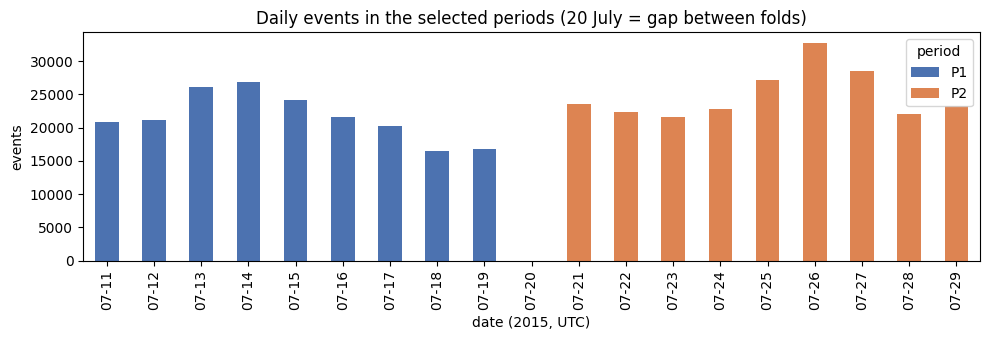

In [17]:
all_days = pd.date_range(P1.start, P2.end, freq="D", inclusive="left").strftime("%m-%d")
daily = (reloaded.assign(day=pd.to_datetime(reloaded["timestamp"], unit="ms", utc=True).dt.strftime("%m-%d"))
         .groupby(["day", "period"]).size().unstack(fill_value=0).reindex(all_days, fill_value=0))
ax = daily.plot(kind="bar", stacked=True, figsize=(10, 3.5), color={"P1": "#4C72B0", "P2": "#DD8452"})
ax.set_xlabel("date (2015, UTC)")
ax.set_ylabel("events")
ax.set_title("Daily events in the selected periods (20 July = gap between folds)")
plt.tight_layout()
plt.show()

Filter result: 417,921 rows (P1 = 194,131, P2 = 223,790) out of 2,756,101 raw rows. 90 (P1 = 33, P2 = 57) exact duplicate rows were dropped. The first/last events in the table above lie inside the period bounds, which proves the filter works.

### 2.1.3 Subgraph composition (Python API + Cypher)

The filtered CSV is imported into Neo4j (after a reset, so the notebook can be re-run):

In [18]:
reset_database(driver, DB)
started = time.perf_counter()
imported_rows = import_events(driver, FILTERED_EVENTS_CSV, DB, progress=False)
print(f"{imported_rows:,} rows imported in {time.perf_counter() - started:.1f} seconds")

417,921 rows imported in 105.1 seconds


In [19]:
queries = {
    "Node composition": cypher.NODE_COMPOSITION,
    "Relationship composition": cypher.RELATIONSHIP_COMPOSITION,
    "Relationships per period": cypher.PERIOD_COMPOSITION,
    "Active nodes per period": cypher.ACTIVE_NODES_PER_PERIOD,
    "Node overlap between periods": cypher.NODES_IN_BOTH_PERIODS,
    "Relationship schema patterns": cypher.SCHEMA_RELATIONSHIPS,
}
composition = {}
for title, query in queries.items():
    composition[title] = read_df(driver, query, DB)
    print(f"{title}-{query}")
    display(composition[title])

Node composition-
MATCH (n)
RETURN labels(n)[0] AS node_type, count(*) AS total
ORDER BY total DESC



,node_type,total
0,Visitor,235261
1,Item,95259


Relationship composition-
MATCH ()-[r]->()
RETURN type(r) AS relationship_type, count(*) AS total
ORDER BY total DESC



,relationship_type,total
0,VIEWED,404642
1,ADDED_TO_CART,9926
2,BOUGHT,3353


Relationships per period-
MATCH (v:Visitor)-[r]->(i:Item)
WHERE r.period IS NOT NULL
RETURN r.period AS period,
       type(r) AS relationship_type,
       count(*) AS relationships,
       count(DISTINCT v) AS unique_visitors,
       count(DISTINCT i) AS unique_items
ORDER BY period, relationships DESC



...

,period,active_visitors,active_items,total_relationships
0,P1,116674,63184,194131
1,P2,122565,65038,223790


Node overlap between periods-
MATCH (n)
WHERE n:Visitor OR n:Item
WITH n, COLLECT {
    MATCH (n)-[r]-()
    WHERE r.period IS NOT NULL
    RETURN DISTINCT r.period
} AS periods
RETURN labels(n)[0] AS node_type,
       sum(CASE WHEN periods = ['P1'] THEN 1 ELSE 0 END) AS only_P1,
       sum(CASE WHEN periods = ['P2'] THEN 1 ELSE 0 END) AS only_P2,
       sum(CASE WHEN size(periods) = 2 THEN 1 ELSE 0 END) AS both_P1_and_P2
ORDER BY node_type DESC



,node_type,only_P1,only_P2,both_P1_and_P2
0,Visitor,112696,118587,3978
1,Item,30221,32075,32963


Relationship schema patterns-
MATCH (a)-[r]->(b)
RETURN DISTINCT labels(a)[0] AS source_label, type(r) AS relationship, labels(b)[0] AS target_label
ORDER BY relationship



,source_label,relationship,target_label
0,Visitor,ADDED_TO_CART,Item
1,Visitor,BOUGHT,Item
2,Visitor,VIEWED,Item


In [20]:
# Cross-check the Cypher results
nodes = composition["Node composition"].set_index("node_type")["total"]
rels = composition["Relationship composition"].set_index("relationship_type")["total"]
assert nodes["Visitor"] == reloaded["visitorid"].nunique()
assert nodes["Item"] == reloaded["itemid"].nunique()
assert rels.sum() == len(reloaded)
print(f"Total nodes = {nodes.sum():,} | total relationships = {rels.sum():,} = number of CSV rows.")

Total nodes = 330,520 | total relationships = 417,921 = number of CSV rows.


**Subgraph Composition**

The subgraph is a directed bipartite graph with 2 node types and 3 relationship types:

| Node type | Count | Meaning |
|---|---:|---|
| `Visitor` | 235,261 | unique visitors active in P1 and/or P2 |
| `Item` | 95,259 | unique products touched in P1 and/or P2 |
| Total | 330,520 | |

| Relationship type (Visitor -> Item) | Count |
|---|---:|
| `VIEWED` | 404,642 |
| `ADDED_TO_CART` | 9,926 |
| `BOUGHT` | 3,353 |
| Total | 417,921 (number of rows in `filtered_events.csv`) |

Per period: P1 contains 116,674 active visitors & 63,184 active items, P2 contains 122,565
visitors & 65,038 items. Only 3,978 visitors appear in both periods, whereas 32,963 items appear in both, which means items are far more "persistent" than visitors.

**Cypher Used**

* `MATCH (n) RETURN labels(n)[0] AS node_type, count(*) AS total`: Scans every node, where `labels(n)` returns the list of labels (here every node has exactly one, so the first element is taken). Non-aggregated columns (`node_type`) become the grouping key automatically, and `count(*)` counts per group.
* `MATCH ()-[r]->() RETURN type(r), count(*)`: Directed relationship pattern, where `type(r)` returns the relationship type.
* `WHERE r.period IS NOT NULL` + `count(DISTINCT v)`: Counts relationships & unique nodes per (period, relationship type), where `DISTINCT` is needed because one visitor can have many relationships.
* `COLLECT { MATCH (n)-[r]-() ... RETURN DISTINCT r.period }`: A subquery that gathers the set of periods in which a node is active, where `CASE` then classifies the node as only P1/only P2/both.
* `MATCH (a)-[r]->(b) RETURN DISTINCT labels(a)[0], type(r), labels(b)[0]`: Summarises the schema (label-relationship-label patterns).

#### 2.1.4 Vector Space Modelling in User nodes (`Visitor`)

**Model**

In training data (P1) interactions (training fold), every visitor $u$ becomes a vector in
a space of dimension $|I|$ (number of P1 items):

$$\mathbf{u} = (r_{u,1}, r_{u,2}, \dots, r_{u,|I|}),\qquad
r_{u,i} = \max_{e \in E(u,i)} w(e),\quad w(\texttt{VIEWED})=1,\; w(\texttt{ADDED\_TO\_CART})=2,\; w(\texttt{BOUGHT})=3$$

and $r_{u,i}=0$ when there is no interaction. The weights follow the depth of the shopping funnel (view -> cart -> buy), while the maximum (not the sum) is used so that page refreshes/repeated views do not inflate the weight. Because almost every cell is 0, the matrix is stored as a CSR sparse matrix (only non-zero elements are stored).

In [21]:
print(cypher.INTERACTIONS_IN_PERIOD)
train = read_df(driver, cypher.INTERACTIONS_IN_PERIOD, DB, period=P1.name)
pairs = pair_weights(train)
user_space = build_user_space(pairs)
print(f"P1 interactions from Neo4j: {len(train):,} -> unique (visitor, item) pairs: {len(pairs):,}")
user_profile = describe(user_space)
user_profile.to_frame()


MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WHERE r.period = $period
RETURN v.visitorId AS visitorId, i.itemId AS itemId, type(r) AS relType



P1 interactions from Neo4j: 194,131 -> unique (visitor, item) pairs: 158,684


,Visitor VSM
vectorised object (rows),Visitor
dimension / feature (columns),Item
shape,"116,674 x 63,184"
number of vectors,116674
vector dimension,63184
non-zero elements (nnz),158684
density,0.000022
sparsity,0.999978
mean nnz per vector,1.360063
median nnz per vector,1.0


In [22]:
# A concrete VSM example (matrix excerpt for the first 5 visitors that have 3-4 items)
lengths = pd.Series(np.diff(user_space.matrix.indptr), index=user_space.row_ids)
sample_users = lengths[lengths.between(3, 4)].index[:5]
excerpt = pd.concat({int(u): user_space.vector(u) for u in sample_users}, axis=1).fillna(0).T
excerpt.index.name = "visitorId"
display(excerpt)

heaviest = int(lengths.idxmax())
print(f"Visitor with the longest vector: {heaviest} ({lengths.max()} non-zero items) -> likely a crawler/bot")

Item,86324,376793,381636,179725,223820,361734,22436,175245,245510,299038,172914,181102,433165,92493,230223,261288
visitorId,,,,,,,,,,,,,,,,
353,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
889,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
921,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1028,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0
1592,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0


Visitor with the longest vector: 371606 (686 non-zero items) -> likely a crawler/bot


,Visitor-Visitor projection
nodes,116674
edges,688049
possible node pairs n(n-1)/2,6806352801
density,0.000101
mean degree,11.794384
median degree,3.0
max degree,4129
isolated nodes (degree 0),24427
% isolated nodes,20.936113
connected components (excluding isolated nodes),12394


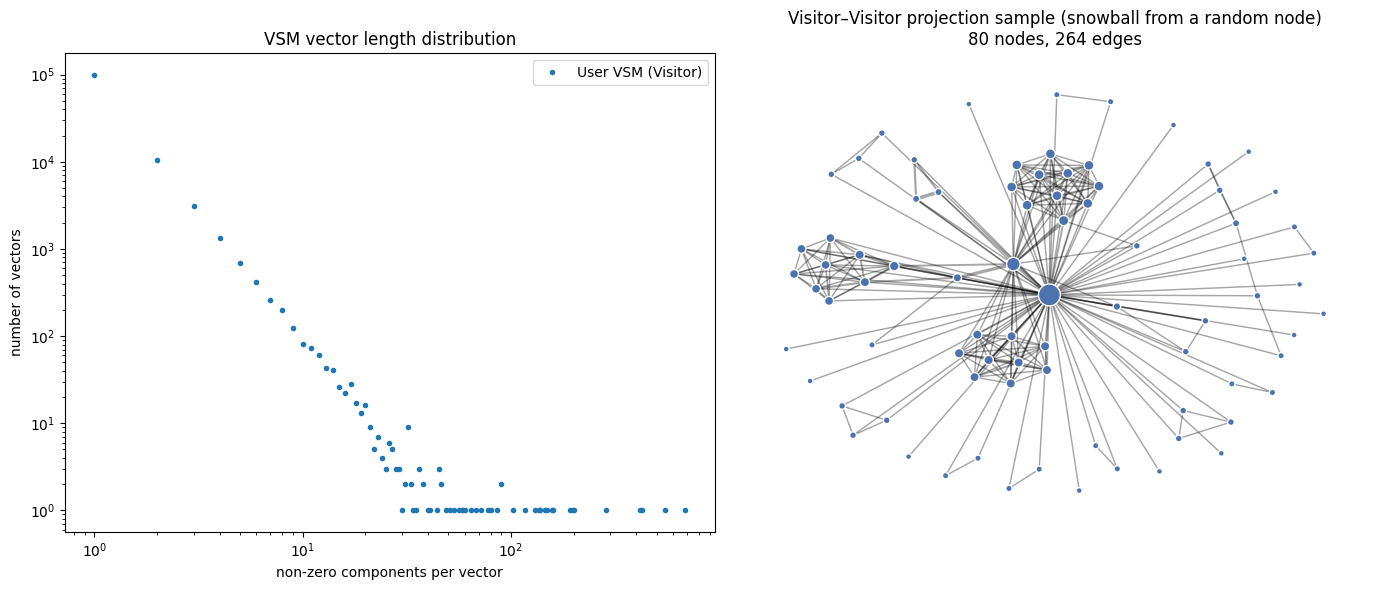

In [23]:
item_space = user_space.transpose()   # also used for the comparison plot
user_projection_stats = projection_stats(user_space)
display(user_projection_stats.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_vector_lengths({"User VSM (Visitor)": user_space}, axes[0])
draw_projection(sample_projection_graph(user_space, max_nodes=80, seed=RANDOM_SEED), axes[1],
                "Visitor–Visitor projection sample (snowball from a random node)", "#4C72B0")
plt.tight_layout()
plt.show()

**User VSM characteristics**

* **Shape** (116,674 × 63,184) -> 116,674 visitor vectors, each of dimension 63,184 (one dimension per item).
* **nnz** 158,684 out of ~7.37 billion cells -> density ≈ 2.15 × 10⁻⁵ (sparsity ≈ 99.998%). As a dense float64 matrix it
  would need ±59 GB, while CSR needs only ±2.37 MB.
* **Vector length**: mean 1.36 items, median 1, maximum 686, 85.19% of visitors have only 1 item. The log-log distribution on the left is long-tailed (power-law), where a few very active visitors (probably bots), while the majority look at a single product.
* **Weights**: 154,508 cells with value 1, 2,811 with value 2, 1,365 with value 3 -> 97% of the cells are 1 (view).
* **Visitor–Visitor projection** (two visitors are connected if they touched the same item, where edge weight = number of shared items): 116,674 nodes, 688,049 edges, density ≈ 1.01 × 10⁻⁴, mean degree 11.79, 20.94% isolated nodes, the largest component holds 43.06% of the nodes. Right plot: a local BFS sample of 80 nodes, where it shows cliques (fully connected groups), because all visitors who viewed the same item are automatically connected, plus hub nodes (very active visitors) linked to many other visitors.

#### 2.1.5 Vector Space Modelling in *Item* nodes

The Item VSM is the transpose of the User VSM, where every item $i$ becomes a vector of dimension $|U|$ (number of P1
visitors), $\mathbf{i} = (r_{1,i}, r_{2,i}, \dots, r_{|U|,i})$ with the same weights.

,Item VSM
vectorised object (rows),Item
dimension / feature (columns),Visitor
shape,"63,184 x 116,674"
number of vectors,63184
vector dimension,116674
non-zero elements (nnz),158684
density,0.000022
sparsity,0.999978
mean nnz per vector,2.511459
median nnz per vector,1.0


Top 5 items by unique visitors in P1:


,unique_visitors
5411,420
115323,237
384302,158
445351,145
150103,120


,Item-Item projection
nodes,63184
edges,875149
possible node pairs n(n-1)/2,1996077336
density,0.000438
mean degree,27.701602
median degree,0.0
max degree,2598
isolated nodes (degree 0),33777
% isolated nodes,53.458154
connected components (excluding isolated nodes),3044


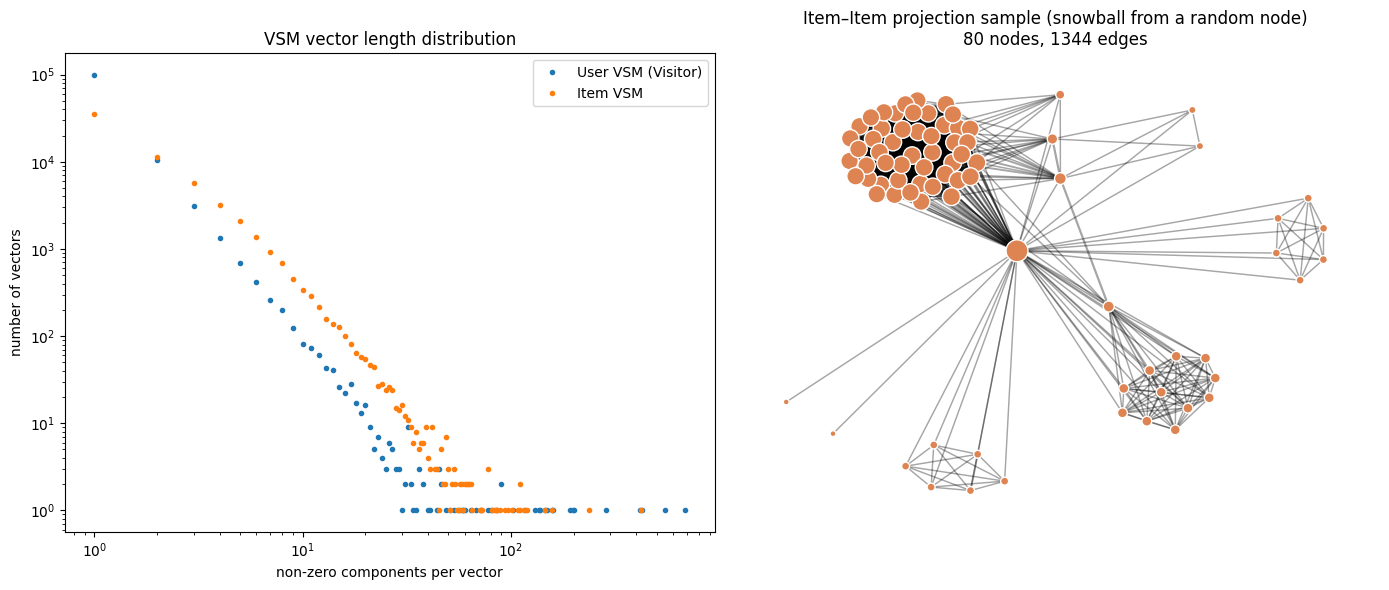

In [24]:
item_profile = describe(item_space)
display(item_profile.to_frame())

popularity = pd.Series(np.diff(item_space.matrix.indptr), index=item_space.row_ids, name="unique_visitors")
print("Top 5 items by unique visitors in P1:")
display(popularity.sort_values(ascending=False, kind="stable").head().to_frame())

item_projection_stats = projection_stats(item_space)
display(item_projection_stats.to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
plot_vector_lengths({"User VSM (Visitor)": user_space, "Item VSM": item_space}, axes[0])
draw_projection(sample_projection_graph(item_space, max_nodes=80, seed=RANDOM_SEED), axes[1],
                "Item–Item projection sample (snowball from a random node)", "#DD8452")
plt.tight_layout()
plt.show()

**Item VSM characteristics**

* **Shape** (63,184 × 116,674) -> 63,184 item vectors, each of dimension 116,674 (one dimension per visitor).
  nnz and density are identical to the User VSM (same matrix, only transposed).
* **Vector length**: mean 2.51 visitors per item (≈1.85× "richer" than user vectors), median 1, maximum 420 (item 5411), where only 56.36% of item vectors contain a single component (vs 85.19% for users).
* **Item–Item projection** (two items are connected if the same visitor touched both co-view/co-purchase): 63,184 nodes, 875,149 edges, density ≈ 4.38 × 10⁻⁴ (≈4× denser), mean degree 27.70, 3.46% isolated nodes (items only viewed by "one-off" visitors), the largest component holds 34.06% of the nodes. The network sample shows clusters of products that are frequently viewed together.

### 2.1.6 Which projection is better (effective/efficient)?

Quantitative comparison of both projections, including the cost of computing the **top-5 cosine neighbours of ever node** (the core KNN step) and how many P1 entities are still "useful" in P2:

In [25]:
test = read_df(driver, cypher.INTERACTIONS_IN_PERIOD, DB, period=P2.name)

started = time.perf_counter()
user_knn_graph = top_k_neighbors(user_space, K_NEIGHBORS)
user_knn_seconds = time.perf_counter() - started

started = time.perf_counter()
item_knn_graph = top_k_neighbors(item_space, K_NEIGHBORS)
item_knn_seconds = time.perf_counter() - started


def knn_summary(knn, seconds, space, test_ids):
    return pd.Series({
        "top-5 cosine time for all nodes (s)": round(seconds, 2),
        "nodes with >=1 neighbour": knn["sourceId"].nunique(),
        "mean neighbour cosine": round(knn["score"].mean(), 4),
        "% neighbours with cosine = 1 (not discriminative)": round(100 * (knn["score"].round(10) == 1).mean(), 2),
        "% P2 entities already known in P1 (reusable)": round(100 * np.isin(test_ids, space.row_ids).mean(), 2),
    }, dtype=object)


rows = ["number of vectors", "vector dimension", "mean nnz per vector", "% vectors with only 1 nnz"]
proj_rows = ["edges", "possible node pairs n(n-1)/2", "density", "mean degree",
             "% isolated nodes", "% nodes in largest component", "adjacency CSR memory (MB)"]
comparison = pd.DataFrame({
    "User projection (Visitor–Visitor)": pd.concat([
        user_profile[rows], user_projection_stats[proj_rows],
        knn_summary(user_knn_graph, user_knn_seconds, user_space, test["visitorId"].unique())]),
    "Item projection (Item–Item)": pd.concat([
        item_profile[rows], item_projection_stats[proj_rows],
        knn_summary(item_knn_graph, item_knn_seconds, item_space, test["itemId"].unique())]),
})
comparison

,User projection (Visitor–Visitor),Item projection (Item–Item)
number of vectors,116674,63184
vector dimension,63184,116674
mean nnz per vector,1.360063,2.511459
% vectors with only 1 nnz,85.194645,56.357622
edges,688049,875149
possible node pairs n(n-1)/2,6806352801,1996077336
density,0.000101,0.000438
mean degree,11.794384,27.701602
% isolated nodes,20.936113,53.458154
% nodes in largest component,43.064436,34.062421


**Conclusion: The Item projection (Item–Item) is better**, because:

**Efficient**
1. 63,184 vs 116,674 nodes -> the space of possible pairs, $n(n-1)/2$, is 3.41× smaller (≈ 2.00 billion vs ≈ 6.81 billion). This is the upper bound of an *all-pairs* comparison ($O(n^2)$). The sparse implementation only computes pairs that are actually neighbours (projection edges), and the item projection in fact has more edges (875,149 vs 688,049).
2. The practical efficiency evidence is therefore the measured time: computing the top-5 cosine neighbours of every node is roughly 2.5–3.5× faster for the item projection.

**Effective**
3. Item vectors are more informative: mean 2.51 vs 1.36 non-zero components, where 85.19% of user vectors contain a single item, so the cosine between users is very often exactly 1 (68.30% of user neighbours have cosine 1 vs 21.23% for items), so neighbours tie and the truly similar ones cannot be distinguished.
4. More stable/reusable, because 50.68% of the items that appear in P2 are already known in P1, whereas only 3.25% of P2 visitors appeared in P1. Item similarities learned in P1 remain useful in P2 for any visitor (including new ones), whereas user similarities only help the few returning visitors.

The item projection has more edges (875,149 vs 688,049, mostly from visitors with extreme
activity forming large cliques) and 53.46% isolated items (vs 20.94% isolated users). The adjacency memory stays small (±14.3 MB), and isolated items simply have no co-occurrence evidence, so it is correct that they get no neighbours.

### 2.1.7 Similarity computation on the projected graph (Python)

Based on 2.1.6, similarity is computed on the **Item–Item projection** using **cosine similarity** on the Item VSM:

$$\cos(\mathbf{i},\mathbf{j}) = \frac{\mathbf{i}\cdot\mathbf{j}}{\lVert\mathbf{i}\rVert\,\lVert\mathbf{j}\rVert}
 = \frac{\sum_{u} r_{u,i}\, r_{u,j}}{\sqrt{\sum_u r_{u,i}^2}\,\sqrt{\sum_u r_{u,j}^2}}$$

Eevery VSM row is L2-normalised (`sklearn.preprocessing.normalize`), then the sparse matrix product $\hat{X}\hat{X}^\top$ yields the cosine of all pairs at once. Non zero values only appear for pairs that are neighbours in the projection. For every item the K = 5 neighbours are kept with a deterministic order (cosine descending -> number of shared visitors (`common`) descending -> `itemId` ascending).

In [26]:
print(inspect.getsource(top_k_neighbors))
ref_item = int(popularity.sort_values(ascending=False, kind="stable").index[0])
print(f"Reference item: {ref_item} (unique visitors in P1 = {popularity[ref_item]})")

python_top5 = most_similar(item_space, ref_item, 5)
assert python_top5[["targetId", "score"]].reset_index(drop=True).equals(
    item_knn_graph.loc[item_knn_graph["sourceId"] == ref_item, ["targetId", "score"]].reset_index(drop=True))
print(f"Item KNN graph: {len(item_knn_graph):,} neighbour pairs for {item_knn_graph['sourceId'].nunique():,} items")
python_top5

def top_k_neighbors(space: VectorSpace, k: int) -> pd.DataFrame:
    similarity = cosine_matrix(space)
    common = co_occurrence(space)
    if not np.array_equal(similarity.indptr, common.indptr):
        raise ValueError("Cosine and co-occurrence must have the same non-zero pattern")

    parts = []
    for row in range(similarity.shape[0]):
        lo, hi = similarity.indptr[row], similarity.indptr[row + 1]
        if lo == hi:
            continue
        targets = space.row_ids[similarity.indices[lo:hi]]
        scores = similarity.data[lo:hi]
        shared = common.data[lo:hi]
        best = _rank(targets, scores, shared, k)
        parts.append(
            pd.DataFrame(
                {
                    "sourceId": space.row_ids[row],
                    "rank": np.arange(1, len(best) + 1),
                    "targetId": targets[best],
                    "score": scores[best],
                    "common": shared[best],
                }
            )
        )
    retur

,sourceId,rank,targetId,score,common
0,5411,1,193409,0.162057,13
1,5411,2,37807,0.122141,8
2,5411,3,33030,0.105388,9
3,5411,4,459936,0.093734,7
4,5411,5,192288,0.086367,1


##### (a) Cypher returning the 5 records with the highest similarity to the reference item

The following query computes exactly the same cosine directly in Neo4j from the P1 interaction relationships (weights passed in the `$weights` parameter), as an independent check of the Python result:
1. `MATCH (ref)<-[r1]-(v:Visitor)` + `max($weights[type(r1)])` -> the reference item's vector component per visitor ($r_{v,ref}$).
2. `MATCH (v)-[r2]->(other:Item)` -> every other item touched by the same visitors (= neighbours in the Item–Item projection), component $r_{v,other}$.
3. `sum(wRef * wOther)` = dot product, where `count(v)` = number of shared visitors.
4. Two `CALL (x) { ... }` subqueries compute the L2 norm $\sqrt{\sum_u r_{u,x}^2}$ of the reference and the candidate.
5. `ORDER BY round(cosine, 10) DESC, commonVisitors DESC, itemId ASC LIMIT 5`, the same ordering as in Python.

In [27]:
print(cypher.COSINE_TOP_ITEMS)
cypher_top5 = read_df(driver, cypher.COSINE_TOP_ITEMS, DB, refItemId=ref_item, period=P1.name,
                      weights=RELATIONSHIP_WEIGHTS, limit=5)
display(cypher_top5)
assert cypher_top5["itemId"].tolist() == python_top5["targetId"].tolist()
assert np.allclose(cypher_top5["cosine"], python_top5["score"])
print("Cypher top-5 is identical to the Python top-5.")


MATCH (ref:Item {itemId: $refItemId})<-[r1]-(v:Visitor)
WHERE r1.period = $period
WITH ref, v, max($weights[type(r1)]) AS wRef
MATCH (v)-[r2]->(other:Item)
WHERE r2.period = $period AND other <> ref
WITH ref, other, v, wRef, max($weights[type(r2)]) AS wOther
WITH ref, other, sum(wRef * wOther) AS dot, count(v) AS commonVisitors
CALL (ref) {
    MATCH (ref)<-[r]-(u:Visitor) WHERE r.period = $period
    WITH u, max($weights[type(r)]) AS w
    RETURN sqrt(sum(w * w)) AS normRef
}
CALL (other) {
    MATCH (other)<-[r]-(u:Visitor) WHERE r.period = $period
    WITH u, max($weights[type(r)]) AS w
    RETURN sqrt(sum(w * w)) AS normOther
}
WITH other, commonVisitors, dot / (normRef * normOther) AS cosine
RETURN other.itemId AS itemId, cosine, commonVisitors
ORDER BY round(cosine, 10) DESC, commonVisitors DESC, itemId ASC
LIMIT $limit



,itemId,cosine,commonVisitors
0,193409,0.162057,13
1,37807,0.122141,8
2,33030,0.105388,9
3,459936,0.093734,7
4,192288,0.086367,1


Cypher top-5 is identical to the Python top-5.


In [28]:
run_autocommit(driver, cypher.DELETE_SIMILARITIES, DB)
neighbor_ids = python_top5["targetId"].tolist()
print(cypher.SIMILARITY_COUNT)
display(read_df(driver, cypher.SIMILARITY_COUNT, DB))
schema_before = read_df(driver, cypher.SCHEMA_RELATIONSHIPS, DB)
before_rows = read_df(driver, cypher.INTERACTION_SUBGRAPH, DB, refItemId=ref_item, period=P1.name, itemIds=neighbor_ids)
display(schema_before)
print(f"Subgraph before: {len(before_rows)} interaction relationships")


MATCH ()-[s]->() WHERE type(s) = 'SIMILAR'
RETURN count(s) AS similar_relationships



,similar_relationships
0,0


,source_label,relationship,target_label
0,Visitor,ADDED_TO_CART,Item
1,Visitor,BOUGHT,Item
2,Visitor,VIEWED,Item


Subgraph before: 71 interaction relationships


#### (b) Writing the similarity values back into the graph

The whole item KNN graph (K = 5 per item, including the 5 neighbours of the reference item) is written as `(:Item)-[:SIMILAR {score, rank, commonVisitors, metric, period}]->(:Item)` relationships in batches (`UNWIND $rows`). `MERGE` makes the write idempotent.

In [29]:
print(cypher.WRITE_SIMILARITIES)
written = write_in_batches(driver, cypher.WRITE_SIMILARITIES, to_records(item_knn_graph), DB, period=P1.name)
print(f"{written:,} SIMILAR relationships written")

print(cypher.SIMILAR_ITEMS_OF)
graph_top5 = read_df(driver, cypher.SIMILAR_ITEMS_OF, DB, refItemId=ref_item)
display(graph_top5)
assert graph_top5["itemId"].tolist() == neighbor_ids
display(read_df(driver, cypher.SIMILARITY_COUNT, DB))


UNWIND $rows AS row
MATCH (a:Item {itemId: row.sourceId})
MATCH (b:Item {itemId: row.targetId})
MERGE (a)-[s:SIMILAR]->(b)
SET s.score = row.score,
    s.rank = row.rank,
    s.commonVisitors = row.common,
    s.metric = 'cosine',
    s.period = $period



98,331 SIMILAR relationships written

MATCH (ref:Item {itemId: $refItemId})-[s:SIMILAR]->(other:Item)
RETURN ref.itemId AS refItemId, s.rank AS rank, other.itemId AS itemId,
       s.score AS score, s.commonVisitors AS commonVisitors, s.metric AS metric
ORDER BY s.rank



,refItemId,rank,itemId,score,commonVisitors,metric
0,5411,1,193409,0.162057,13,cosine
1,5411,2,37807,0.122141,8,cosine
2,5411,3,33030,0.105388,9,cosine
3,5411,4,459936,0.093734,7,cosine
4,5411,5,192288,0.086367,1,cosine


,similar_relationships
0,98331


### 2.1.8 The graph before and after the similarity computation

* **Cypher before**: The P1 interaction subgraph around the reference item: the visitors that connect the reference item with its 5 neighbouring items (`INTERACTION_SUBGRAPH`). * * **Cypher after**: The same subgraph plus the new `(ref)-[:SIMILAR]->(other)` relationships (`SIMILARITY_SUBGRAPH`).

BEFORE: 
MATCH (ref:Item {itemId: $refItemId})<-[r1]-(v:Visitor)-[r2]->(other:Item)
WHERE r1.period = $period AND r2.period = $period AND other.itemId IN $itemIds
RETURN DISTINCT 'Visitor' AS sourceLabel, v.visitorId AS sourceId, type(r1) AS relType,
       'Item' AS targetLabel, ref.itemId AS targetId
UNION
MATCH (ref:Item {itemId: $refItemId})<-[r1]-(v:Visitor)-[r2]->(other:Item)
WHERE r1.period = $period AND r2.period = $period AND other.itemId IN $itemIds
RETURN DISTINCT 'Visitor' AS sourceLabel, v.visitorId AS sourceId, type(r2) AS relType,
       'Item' AS targetLabel, other.itemId AS targetId

AFTER: 
MATCH (ref:Item {itemId: $refItemId})-[s:SIMILAR]->(other:Item)
RETURN 'Item' AS sourceLabel, ref.itemId AS sourceId, 'SIMILAR' AS relType,
       'Item' AS targetLabel, other.itemId AS targetId, s.score AS score



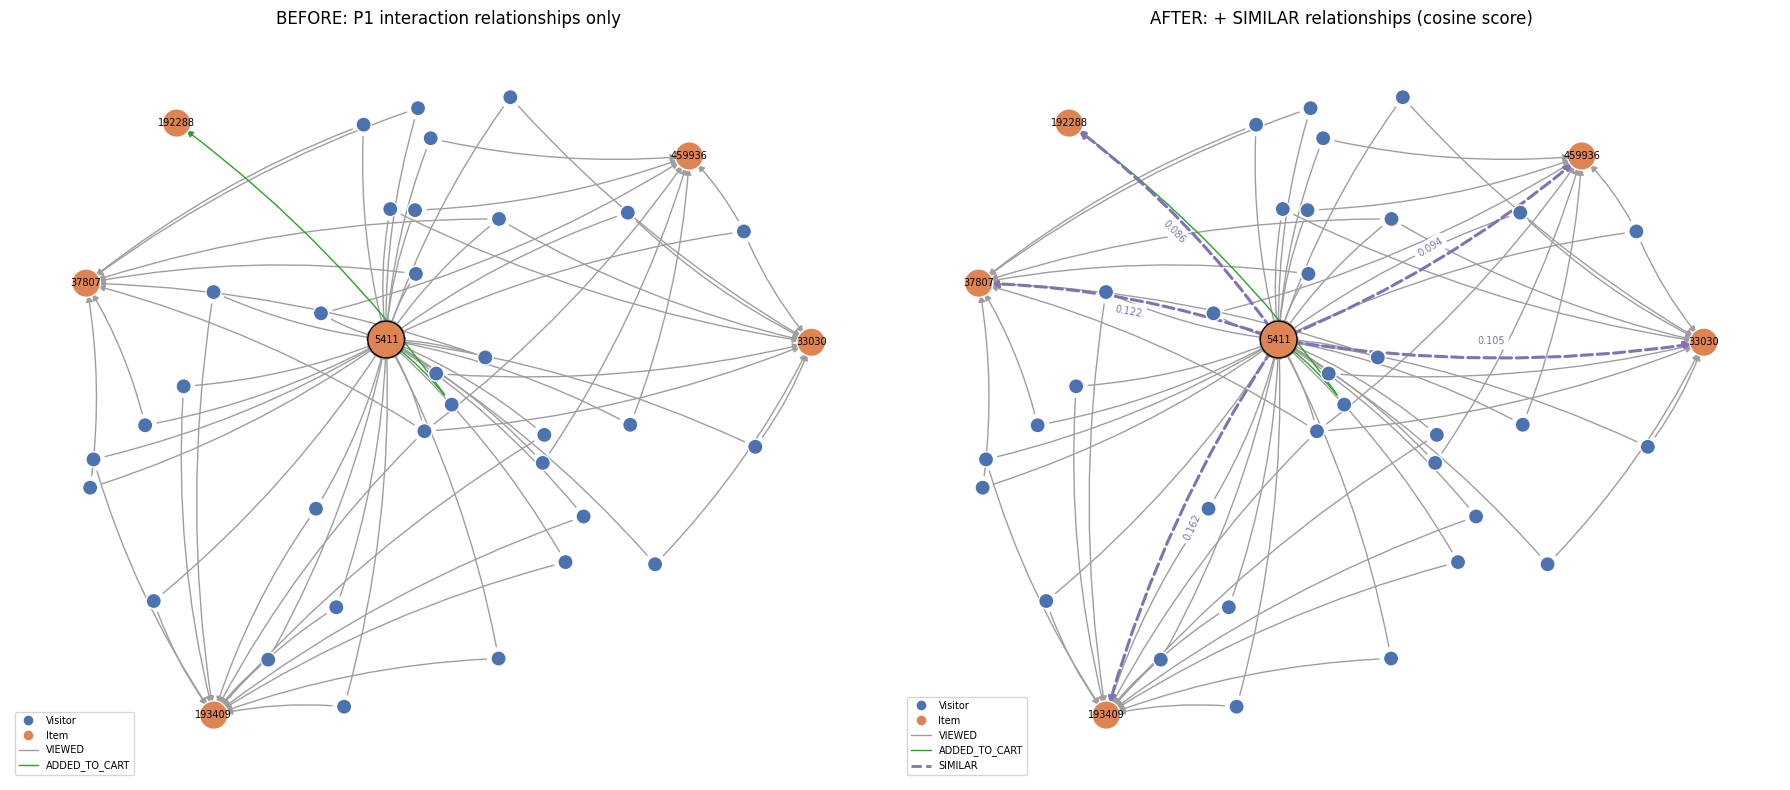

Relationship schema after:


,source_label,relationship,target_label
0,Visitor,ADDED_TO_CART,Item
1,Visitor,BOUGHT,Item
2,Item,SIMILAR,Item
3,Visitor,VIEWED,Item


In [30]:
print("BEFORE:", cypher.INTERACTION_SUBGRAPH)
print("AFTER:", cypher.SIMILARITY_SUBGRAPH)
after_rows = pd.concat([
    read_df(driver, cypher.INTERACTION_SUBGRAPH, DB, refItemId=ref_item, period=P1.name, itemIds=neighbor_ids),
    read_df(driver, cypher.SIMILARITY_SUBGRAPH, DB, refItemId=ref_item),
], ignore_index=True)

before_graph, after_graph = graph_from_rows(before_rows), graph_from_rows(after_rows)
fig, axes = plt.subplots(1, 2, figsize=(18, 8))
layout = draw_property_graph(after_graph, axes[1], "AFTER: + SIMILAR relationships (cosine score)", highlight={f"Item:{ref_item}"})
draw_property_graph(before_graph, axes[0], "BEFORE: P1 interaction relationships only", pos=layout, highlight={f"Item:{ref_item}"})
plt.tight_layout()
plt.show()

print("Relationship schema after:")
read_df(driver, cypher.SCHEMA_RELATIONSHIPS, DB)

**Interpretation**

Before the computation, the reference item 5411 and its neighbours are only connected
indirectly through visitors (2-hop paths `Item <- Visitor -> Item`), and the schema only contains the 3 `Visitor -> Item` patterns. After the computation a new schema pattern `Item -[SIMILAR]-> Item` appears (98,331 relationships for all items), so similarity can be read directly and its cosine score is printed on the dashed purple edges.

### 2.2 Analytics

#### 2.2.1 Random user selection and KNN recommendation

**Random Process**
1. Ground truth = the items each visitor interacted with in P2.
2. Candidates = visitors with a P1 history and activity in P2.
3. Candidates are sorted ascending, then shuffled with `np.random.default_rng(seed=42).permutation(...)`.
4. The first candidate in that shuffled order for which Item-KNN (k = 5) can produce ≥ 3 items is taken. Skipped candidates are printed for transparency. This query is equivalent to drawing uniformly at random from the valid candidates, and it always returns the same user for the same seed.

**KNN model (Item-KNN)**
For user $u$ with history $H_u$ (P1 items), $N_5(i)$ is the set of the 5 items most similar (cosine) to item $i$, which are exactly the `SIMILAR` relationships in the graph. The score of a candidate $j \notin H_u$ is

$$\text{score}(u, j) = \sum_{i \in H_u,\; j \in N_5(i)} \cos(i, j)\cdot r_{u,i}$$

and the 3 highest scores are kept (ties -> `itemId` ascending). Items the user already interacted with in P1 are not advertised again.

In [31]:
truth = ground_truth(test)
candidates = eligible_users(user_space, truth)
item_knn = ItemKNNRecommender(user_space, K_NEIGHBORS)

target_user, skipped = pick_random_user(
    candidates, RANDOM_SEED, is_valid=lambda u: len(item_knn.recommend(u, N_RECOMMENDATIONS)) == N_RECOMMENDATIONS)
print(f"Candidates (active in P1 & P2): {len(candidates):,} visitors")
print(f"Skipped because they get < 3 candidate items: {skipped}")
print(f"Selected user (seed={RANDOM_SEED}): visitorId = {target_user}")

Candidates (active in P1 & P2): 3,978 visitors
Skipped because they get < 3 candidate items: [859572]
Selected user (seed=42): visitorId = 1399785


#### (a) Python script for the KNN recommendation

In [32]:
for method in (ItemKNNRecommender.__init__, ItemKNNRecommender.contributions, ItemKNNRecommender.recommend):
    print(inspect.getsource(method))
history = user_space.vector(target_user)
print(f"P1 history of visitor {target_user} (itemId -> weight):")
display(history.to_frame())

contributions = item_knn.contributions(target_user)
print("Contribution of the KNN neighbours (k=5) of every history item (candidates the user has not seen):")
display(contributions)

    def __init__(self, user_space: VectorSpace, k: int):
        self.user_space = user_space
        self.k = k
        self.neighbors = top_k_neighbors(user_space.transpose(), k)

    def contributions(self, user_id: int) -> pd.DataFrame:
        history = self.user_space.vector(user_id)
        table = self.neighbors[
            self.neighbors["sourceId"].isin(history.index) & ~self.neighbors["targetId"].isin(history.index)
        ]
        table = table.assign(r_ui=table["sourceId"].map(history))
        return table.assign(contribution=table["score"] * table["r_ui"]).reset_index(drop=True)

    def recommend(self, user_id: int, n: int) -> pd.DataFrame:
        parts = self.contributions(user_id)
        return _top_n(parts.groupby("targetId")["contribution"].sum(), n)

P1 history of visitor 1399785 (itemId -> weight):


,weight
Item,
73200,1.0


Contribution of the KNN neighbours (k=5) of every history item (candidates the user has not seen):


,sourceId,rank,targetId,score,common,r_ui,contribution
0,73200,1,251129,0.377964,1,1.0,0.377964
1,73200,2,269333,0.218218,1,1.0,0.218218
2,73200,3,85914,0.119523,1,1.0,0.119523
3,73200,4,264392,0.104828,1,1.0,0.104828
4,73200,5,108458,0.101015,1,1.0,0.101015


#### (b) The 3 advertised items (k = 5)

In [33]:
recommendations = item_knn.recommend(target_user, N_RECOMMENDATIONS)
display(recommendations)

print(cypher.RECOMMEND_FROM_SIMILAR)
graph_recs = read_df(driver, cypher.RECOMMEND_FROM_SIMILAR, DB, visitorId=target_user, period=P1.name,
                     weights=RELATIONSHIP_WEIGHTS, limit=N_RECOMMENDATIONS)
display(graph_recs)
assert graph_recs["itemId"].tolist() == recommendations["itemId"].tolist()
assert np.allclose(graph_recs["score"], recommendations["score"])
print("Cypher recommendation is identical to the Python script.")

,rank,itemId,score
0,1,251129,0.377964
1,2,269333,0.218218
2,3,85914,0.119523



MATCH (v:Visitor {visitorId: $visitorId})-[r]->(seen:Item)
WHERE r.period = $period
WITH v, seen, max($weights[type(r)]) AS w
MATCH (seen)-[s:SIMILAR]->(candidate:Item)
WHERE NOT EXISTS { MATCH (v)-[r2]->(candidate) WHERE r2.period = $period }
WITH candidate, sum(w * s.score) AS score
RETURN candidate.itemId AS itemId, score
ORDER BY round(score, 10) DESC, itemId ASC
LIMIT $limit



,itemId,score
0,251129,0.377964
1,269333,0.218218
2,85914,0.119523


Cypher recommendation is identical to the Python script.


,visitorId,rank,itemId,score,k,method
0,1399785,1,251129,0.377964,5,item-knn-cosine
1,1399785,2,269333,0.218218,5,item-knn-cosine
2,1399785,3,85914,0.119523,5,item-knn-cosine


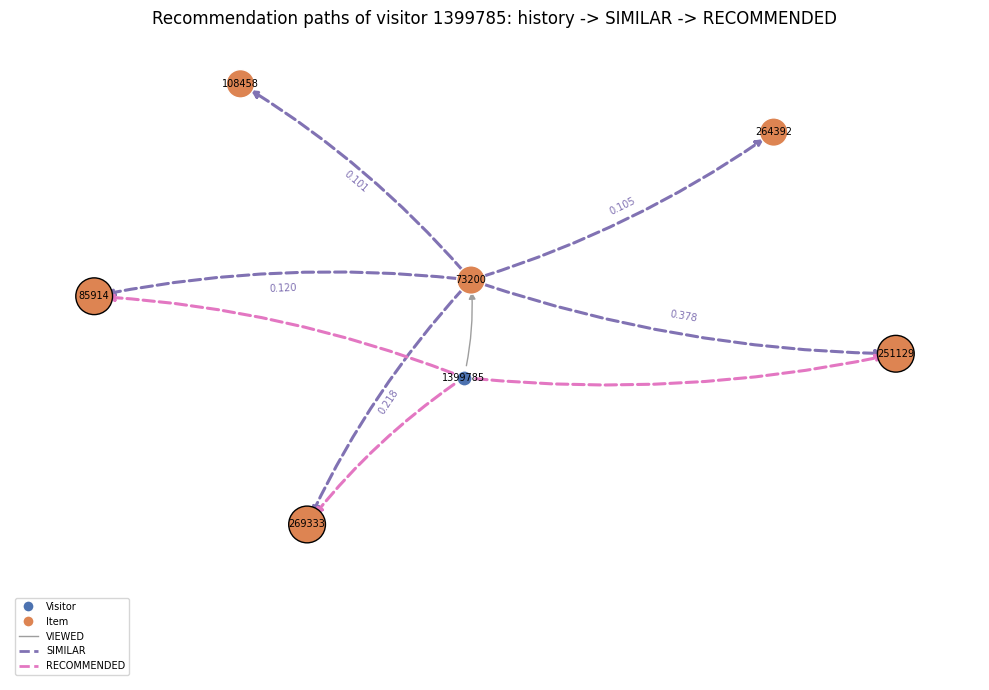

In [34]:
# Store the ads in the graph as RECOMMENDED relationships and display them.
write(driver, cypher.WRITE_RECOMMENDATIONS, DB, visitorId=target_user, rows=to_records(recommendations[["rank", "itemId", "score"]]),
      k=K_NEIGHBORS, method="item-knn-cosine")
display(read_df(driver, cypher.RECOMMENDATIONS_OF, DB, visitorId=target_user))

seen_rows = (train[train["visitorId"] == target_user]
             .assign(sourceLabel="Visitor", targetLabel="Item")
             .rename(columns={"visitorId": "sourceId", "itemId": "targetId"}))
similar_rows = contributions.assign(sourceLabel="Item", targetLabel="Item", relType="SIMILAR")
rec_rows = recommendations.assign(sourceLabel="Visitor", sourceId=target_user, targetLabel="Item",
                                  targetId=recommendations["itemId"], relType="RECOMMENDED")
base = ["sourceLabel", "sourceId", "relType", "targetLabel", "targetId"]
explain_graph = graph_from_rows(pd.concat([seen_rows[base], similar_rows[base + ["score"]], rec_rows[base]],
                                          ignore_index=True))
fig, ax = plt.subplots(figsize=(10, 7))
draw_property_graph(explain_graph, ax, f"Recommendation paths of visitor {target_user}: history -> SIMILAR -> RECOMMENDED",
                    highlight={f"Item:{i}" for i in recommendations["itemId"]}, label_labels=("Item", "Visitor"))
plt.tight_layout()
plt.show()

**Comparison**

For completeness the same user is also scored with User-KNN (the 5 most similar visitors, score $\sum_{v \in N_5(u)} \cos(u,v)\, r_{v,j}$) and a popularity baseline (the most viewed P1 items that the user has not seen).

In [35]:
user_knn = UserKNNRecommender(user_space, K_NEIGHBORS)
popular = PopularityRecommender(user_space)
print("5 nearest neighbours (User-KNN):")
display(user_knn.neighbors(target_user))
pd.concat({
    "Item-KNN (main)": recommendations.set_index("rank")[["itemId", "score"]],
    "User-KNN": user_knn.recommend(target_user, N_RECOMMENDATIONS).set_index("rank")[["itemId", "score"]],
    "Popularity": popular.recommend(target_user, N_RECOMMENDATIONS).set_index("rank")[["itemId", "score"]],
}, axis=1)

5 nearest neighbours (User-KNN):


,sourceId,rank,targetId,score,common
0,1399785,1,21376,1.000000,1
1,1399785,2,869934,1.000000,1
2,1399785,3,1200018,1.000000,1
3,1399785,4,537108,0.707107,1
4,1399785,5,277731,0.577350,1


Item-KNN (main)           User-KNN           Popularity       
              itemId     score   itemId     score     itemId  score
rank                                                               
1             251129  0.377964   269333  0.707107       5411  420.0
2             269333  0.218218   108458  0.577350     115323  237.0
3              85914  0.119523   264392  0.577350     384302  158.0

**Result**

The randomly selected user is visitor 1399785 (P1 history: 1 item, namely item `73200` with a `VIEWED` relationship (weight 1)). The three items advertised with Item-KNN, k = 5:

| Rank | itemId | KNN score | Origin |
|---|---|---|---|
| 1 | **251129** | 0.377964 | 1st neighbour of item 73200 |
| 2 | **269333** | 0.218218 | 2nd neighbour of item 73200 |
| 3 | **85914** | 0.119523 | 3rd neighbour of item 73200 |

The recommendation computed by the Python script is identical to the result of the Cypher query on the `SIMILAR` relationships and has been stored in the graph as `RECOMMENDED` relationships.

#### 2.2.2 Evaluation: Hit@5 and NDCG@5

Binary relevance is where a recommended item is relevant ($rel_i = 1$) if the visitor actually interacted with it (view / addtocart / transaction) in P2. $L$ = the ordered list of 3 recommendations, $R$ = the set of relevant items.

$$\text{Hit@5} = \mathbb{1}\left[\,L_{1..5} \cap R \neq \varnothing\,\right]$$

$$\text{DCG@5} = \sum_{i=1}^{\min(5,|L|)} \frac{rel_i}{\log_2(i+1)},\qquad
\text{IDCG@5} = \sum_{i=1}^{\min(5,|R|)} \frac{1}{\log_2(i+1)},\qquad
\text{NDCG@5} = \frac{\text{DCG@5}}{\text{IDCG@5}}$$

The list only holds 3 items, so positions 4–5 contribute no *gain*, but IDCG is still computed from $\min(5, |R|)$ relevant items.

In [36]:
recommended_ids = recommendations["itemId"].tolist()
relevant = truth[target_user]
print(f"Relevant items of visitor {target_user} in P2 (|R| = {len(relevant)}): {sorted(relevant)}")
print(f"Recommendations (L): {recommended_ids}")
display(gain_table(recommended_ids, relevant, EVAL_CUTOFF))

hit = hit_at_k(recommended_ids, relevant, EVAL_CUTOFF)
dcg = dcg_at_k(recommended_ids, relevant, EVAL_CUTOFF)
idcg = idcg_at_k(len(relevant), EVAL_CUTOFF)
ndcg = ndcg_at_k(recommended_ids, relevant, EVAL_CUTOFF)
print(f"Hit@5 = {hit}")
print(f"DCG@5 = {dcg:.6f}")
print(f"IDCG@5 = {idcg:.6f}   (= sum 1/log2(i+1) for i = 1..{min(EVAL_CUTOFF, len(relevant))})")
print(f"NDCG@5 = {ndcg:.6f}")

Relevant items of visitor 1399785 in P2 (|R| = 1): [73200]
Recommendations (L): [251129, 269333, 85914]


,rank,itemId,rel_i,1/log2(i+1),gain
0,1,251129,0,1.00000,0.0
1,2,269333,0,0.63093,0.0
2,3,85914,0,0.50000,0.0


Hit@5 = 0
DCG@5 = 0.000000
IDCG@5 = 1.000000   (= sum 1/log2(i+1) for i = 1..1)
NDCG@5 = 0.000000


**Result for visitor 1399785**

In P2 this visitor interacted with only 1 item, `73200`, which is the same item as in their P1 history (a revisit). None of the recommendations is in $R$, so every $rel_i = 0$:

* **Hit@5 = 0**
* DCG@5 = 0; IDCG@5 = $1/\log_2 2$ = 1 (because $|R| = 1$); **NDCG@5 = 0 / 1 = 0**

T0 is not a calculation error. Item-KNN deliberately does not re-advertise items that were already seen, while this visitor's P2 behaviour was to return to the same product. A single user's result is also heavily influenced by chance.

A single user is only one sample. So that the model assessment at all three methods are evaluated on all 3,978 candidates (3-item lists, cut-off @5). The mean of Hit@5 = *Hit Rate*@5.

In [37]:
def evaluate_all(users, relevant_sets):
    results = {}
    for model in (item_knn, user_knn, popular):
        per_user = evaluate(model, users, relevant_sets, N_RECOMMENDATIONS, EVAL_CUTOFF)
        results[model.name] = {
            "users": len(per_user),
            "HitRate@5": per_user["Hit@5"].mean(),
            "NDCG@5": per_user["NDCG@5"].mean(),
            "hits": int(per_user["Hit@5"].sum()),
            "users with 3 recommendations (%)": 100 * (per_user["n_recommended"] == N_RECOMMENDATIONS).mean(),
            "users without recommendations (%)": 100 * (per_user["n_recommended"] == 0).mean(),
        }
    return pd.DataFrame(results).T


evaluate_all(candidates, truth)

,users,HitRate@5,NDCG@5,hits,users with 3 recommendations (%),users without recommendations (%)
Item-KNN,3978.0,0.013575,0.007280,54.0,52.991453,35.268979
User-KNN,3978.0,0.012569,0.006665,50.0,20.663650,63.675214
Popularity,3978.0,0.003519,0.001349,14.0,100.000000,0.000000


Why are the absolute numbers small? Many P2 interactions are revisit* of items already seen in P1 (like visitor 1399785), while the recommender deliberately does not re-advertise items already seen. The cell below measures the share of those revisits and then repeats the evaluation with a ground truth of new items only*(P2 items the user had
not seen in P1), which is a fairer measure of the ability to surface new products.

In [38]:
seen_p1 = {int(u): set(user_space.vector(int(u)).index) for u in candidates}
p2_pairs = sum(len(truth[u]) for u in seen_p1)
repeat_pairs = sum(len(truth[u] & seen_p1[u]) for u in seen_p1)
print(f"P2 (visitor, item) pairs of the candidates: {p2_pairs:,}")
print(f"...that are revisits of P1 items: {repeat_pairs:,} ({100 * repeat_pairs / p2_pairs:.2f}%)")

truth_new = {u: truth[u] - seen_p1[u] for u in seen_p1}
users_new = [u for u in seen_p1 if truth_new[u]]
print(f"Candidates with >=1 new item in P2: {len(users_new):,}")
evaluate_all(users_new, truth_new)

P2 (visitor, item) pairs of the candidates: 12,026
...that are revisits of P1 items: 1,866 (15.52%)
Candidates with >=1 new item in P2: 2,929


,users,HitRate@5,NDCG@5,hits,users with 3 recommendations (%),users without recommendations (%)
Item-KNN,2929.0,0.018436,0.011238,54.0,52.338682,35.984978
User-KNN,2929.0,0.017071,0.010047,50.0,21.543189,63.298054
Popularity,2929.0,0.004780,0.002031,14.0,100.000000,0.000000


**Interpretation of the Evaluation**

* Over all 3,978 candidates, Item-KNN reaches HitRate@5 = 0.0136 (54 hits) and NDCG@5 = 0.0073, User-KNN 0.0126 (50 hits)/0.0067, the popularity baseline 0.0035 (14 hits)/0.0013. Item-KNN is ±3.9× better than popularity and slightly above User-KNN.
* Item-KNN can return 3 recommendations for 53.0% of the candidates, User-KNN for only 20.7%, so that many User-KNN neighbours have cosine 1 but no new item to offer.
* 15.52% of the P2 (visitor, item) pairs are revisits of P1 items (36.3% of the candidates do this). With a ground truth of new items only (2,929 users), Item-KNN's HitRate@5 becomes 0.0184 and NDCG@5 0.0112, so the model ranking stays the same.
* Small absolute values are expected for this data, where interactions are extremely sparse (85% of P1 visitors touch only 1 item), the catalogue has tens of thousands of items, there are only 3 ad slots, and 35.3% of the candidates get no Item-KNN recommendation at all because their history items are isolated in the Item–Item projection.

In [39]:
driver.close()